In [3]:
import json
from pathlib import Path

annotation_file = "/content/annotations.json"
image_folder = Path("/content/images")

with open(annotation_file) as f:
    data = json.load(f)

images = data["images"]
annotations = data["annotations"]

print("Images in JSON:", len(images))
print("Annotations:", len(annotations))

missing = [
    img["file_name"]
    for img in images
    if not (image_folder / img["file_name"]).exists()
]

print("Missing images:", len(missing))
print(missing[:10])

Images in JSON: 70
Annotations: 70
Missing images: 0
[]


In [4]:
!pip install opencv-python-headless

import cv2
import numpy as np
import glob
import zipfile
import os

zip_path = "/content/calibration.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/calibration")

print("Extraction complete")

Extraction complete


In [5]:
import cv2
import numpy as np
import glob
import os

CHECKERBOARD = (7, 9)  # Inner corners
SQUARE_SIZE = 20.0     # mm

# Find all images
images = glob.glob("/content/calibration/**/*.jpg", recursive=True)
images += glob.glob("/content/calibration/**/*.jpeg", recursive=True)
images += glob.glob("/content/calibration/**/*.png", recursive=True)

print("Images found:", len(images))

# Prepare checkerboard points
objp = np.zeros((CHECKERBOARD[0] * CHECKERBOARD[1], 3), np.float32)
objp[:, :2] = np.mgrid[
    0:CHECKERBOARD[0], 0:CHECKERBOARD[1]
].T.reshape(-1, 2)
objp *= SQUARE_SIZE

objpoints = []
imgpoints = []

for image_path in images:
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    ret, corners = cv2.findChessboardCorners(
        gray, CHECKERBOARD, None
    )

    if ret:
        corners2 = cv2.cornerSubPix(
            gray, corners, (11, 11), (-1, -1),
            (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
             30, 0.001)
        )
        objpoints.append(objp)
        imgpoints.append(corners2)

print("Successful detections:", len(objpoints))

if len(objpoints) >= 10:
    ret, camera_matrix, dist_coeffs, rvecs, tvecs = (
        cv2.calibrateCamera(
            objpoints, imgpoints, gray.shape[::-1], None, None
        )
    )

    print("\nRMS Reprojection Error:", ret)
    print("\nCamera Matrix:\n", camera_matrix)
    print("\nDistortion Coefficients:\n", dist_coeffs)

    np.savez(
        "/content/camera_calibration.npz",
        camera_matrix=camera_matrix,
        dist_coeffs=dist_coeffs
    )
    print("\nCalibration saved.")
else:
    print("Not enough successful detections. Check board size and images.")

Images found: 20
Successful detections: 20

RMS Reprojection Error: 1.5109962821420082

Camera Matrix:
 [[3.40812685e+03 0.00000000e+00 2.03674409e+03]
 [0.00000000e+00 3.38885097e+03 1.50541417e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

Distortion Coefficients:
 [[ 0.103903   -0.13466117  0.00341014 -0.0052222  -0.03300959]]

Calibration saved.


In [6]:
total_error = 0

for i in range(len(objpoints)):
    projected_points, _ = cv2.projectPoints(
        objpoints[i], rvecs[i], tvecs[i],
        camera_matrix, dist_coeffs
    )

    error = cv2.norm(
        imgpoints[i], projected_points, cv2.NORM_L2
    ) / len(projected_points)

    total_error += error
    print(f"Image {i+1}: {error:.3f} pixels")

print("\nMean reprojection error:",
      total_error / len(objpoints))

Image 1: 0.208 pixels
Image 2: 0.225 pixels
Image 3: 0.194 pixels
Image 4: 0.197 pixels
Image 5: 0.170 pixels
Image 6: 0.171 pixels
Image 7: 0.200 pixels
Image 8: 0.183 pixels
Image 9: 0.172 pixels
Image 10: 0.181 pixels
Image 11: 0.195 pixels
Image 12: 0.165 pixels
Image 13: 0.168 pixels
Image 14: 0.156 pixels
Image 15: 0.184 pixels
Image 16: 0.224 pixels
Image 17: 0.184 pixels
Image 18: 0.215 pixels
Image 19: 0.191 pixels
Image 20: 0.203 pixels

Mean reprojection error: 0.18941454873080366


In [7]:
from google.colab import files
files.download('/content/camera_calibration.npz')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
import os
import json

with open("/content/annotations.json") as f:
    data = json.load(f)

print("Images in JSON:", len(data["images"]))
print("Annotations:", len(data["annotations"]))
print("Uploaded images:", len(os.listdir("/content/images")))

Images in JSON: 70
Annotations: 70
Uploaded images: 70


In [9]:
import cv2
import numpy as np
import json
from pathlib import Path

cal = np.load("/content/camera_calibration.npz")
camera_matrix = cal["camera_matrix"]
dist_coeffs = cal["dist_coeffs"]

with open("/content/annotations.json") as f:
    coco = json.load(f)

print("Calibration loaded.")
print("Images:", len(coco["images"]))
print("Annotations:", len(coco["annotations"]))

Calibration loaded.
Images: 70
Annotations: 70


In [10]:
import cv2
import numpy as np
import json
from pathlib import Path
from collections import defaultdict
import copy

# Paths
IMAGE_DIR = Path("/content/images")
OUTPUT_DIR = Path("/content/undistorted")
OUTPUT_DIR.mkdir(exist_ok=True)

# Load calibration
cal = np.load("/content/camera_calibration.npz")
K = cal["camera_matrix"]
D = cal["dist_coeffs"]

# Load COCO annotations
with open("/content/annotations.json") as f:
    coco = json.load(f)

new_coco = copy.deepcopy(coco)

# Group annotations by image
annotations_by_image = defaultdict(list)
for ann in new_coco["annotations"]:
    annotations_by_image[ann["image_id"]].append(ann)

successful = 0

for img_info in new_coco["images"]:
    filename = img_info["file_name"]
    image_path = IMAGE_DIR / filename

    image = cv2.imread(str(image_path))
    if image is None:
        print("Missing:", filename)
        continue

    h, w = image.shape[:2]

    # Scale calibration matrix if image dimensions differ
    K_scaled = K.copy()
    K_scaled[0, :] *= w / 4160
    K_scaled[1, :] *= h / 3120

    new_K, roi = cv2.getOptimalNewCameraMatrix(
        K_scaled, D, (w, h), 1, (w, h)
    )

    map_x, map_y = cv2.initUndistortRectifyMap(
        K_scaled, D, None, new_K, (w, h), cv2.CV_32FC1
    )

    undistorted = cv2.remap(
        image, map_x, map_y, cv2.INTER_LINEAR
    )

    # Save corrected image
    cv2.imwrite(str(OUTPUT_DIR / filename), undistorted)

    # Transform each polygon annotation
    for ann in annotations_by_image[img_info["id"]]:
        transformed_segments = []

        for segment in ann["segmentation"]:
            points = np.array(segment, dtype=np.float32).reshape(-1, 1, 2)

            corrected_points = cv2.undistortPoints(
                points, K_scaled, D, P=new_K
            )

            corrected_points = corrected_points.reshape(-1, 2)

            # Clip coordinates to image boundaries
            corrected_points[:, 0] = np.clip(corrected_points[:, 0], 0, w - 1)
            corrected_points[:, 1] = np.clip(corrected_points[:, 1], 0, h - 1)

            transformed_segments.append(
                corrected_points.flatten().tolist()
            )

        ann["segmentation"] = transformed_segments

        # Recalculate bounding box and area from transformed polygon
        all_points = np.concatenate([
            np.array(s).reshape(-1, 2)
            for s in transformed_segments
        ])

        x, y, bw, bh = cv2.boundingRect(
            all_points.astype(np.float32)
        )

        ann["bbox"] = [int(x), int(y), int(bw), int(bh)]

        contour = all_points.astype(np.float32).reshape(-1, 1, 2)
        ann["area"] = float(cv2.contourArea(contour))

    successful += 1

# Save transformed COCO annotations
with open("/content/undistorted/annotations.json", "w") as f:
    json.dump(new_coco, f)

print("Undistorted images:", successful)
print("Annotations:", len(new_coco["annotations"]))
print("Output folder:", OUTPUT_DIR)

Undistorted images: 70
Annotations: 70
Output folder: /content/undistorted


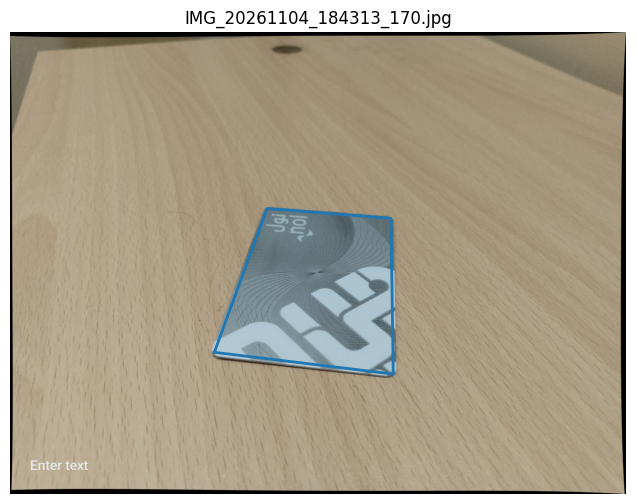

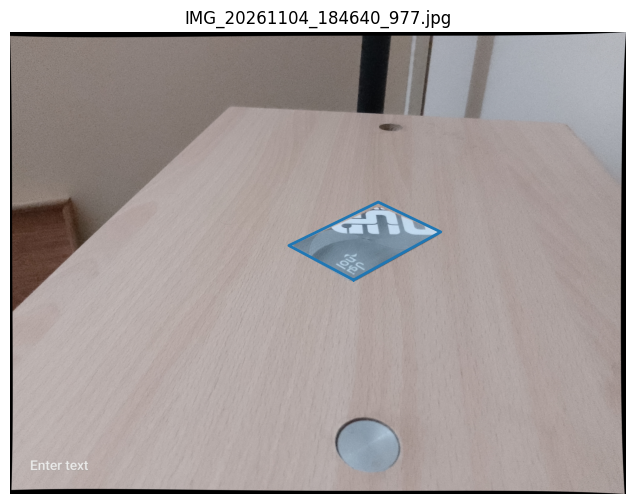

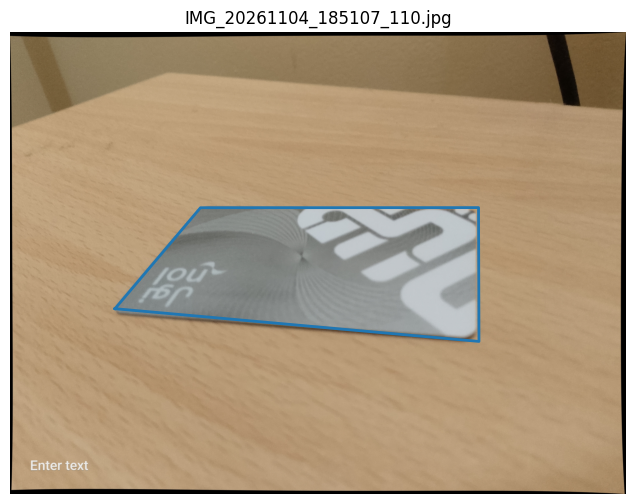

In [11]:
import cv2
import json
import matplotlib.pyplot as plt
from pathlib import Path

with open("/content/undistorted/annotations.json") as f:
    data = json.load(f)

annotations = data["annotations"]
images = data["images"]

selected = [images[0], images[len(images)//2], images[-1]]

for img_info in selected:
    img_path = Path("/content/undistorted") / img_info["file_name"]
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 6))
    plt.imshow(img)

    for ann in annotations:
        if ann["image_id"] == img_info["id"]:
            for seg in ann["segmentation"]:
                points = np.array(seg).reshape(-1, 2)
                plt.plot(
                    np.append(points[:, 0], points[0, 0]),
                    np.append(points[:, 1], points[0, 1]),
                    linewidth=2
                )

    plt.title(img_info["file_name"])
    plt.axis("off")
    plt.show()


In [12]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True
GPU: Tesla T4


In [13]:
import torch
import torchvision
import json
import cv2
import numpy as np
import random
import os

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import (
    maskrcnn_resnet50_fpn,
    MaskRCNN_ResNet50_FPN_Weights
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

# Configuration
DEVICE = torch.device("cuda")
NUM_CLASSES = 2  # Background + Object
EPOCHS = 10
BATCH_SIZE = 2

IMAGE_DIR = Path("/content/undistorted")
ANNOTATION_FILE = IMAGE_DIR / "annotations.json"

with open(ANNOTATION_FILE) as f:
    coco = json.load(f)

# Dataset
class ObjectDataset(Dataset):
    def __init__(self, images, annotations):
        self.images = images
        self.annotations = annotations

        self.ann_map = {}
        for ann in annotations:
            self.ann_map.setdefault(ann["image_id"], []).append(ann)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        info = self.images[idx]
        image = Image.open(IMAGE_DIR / info["file_name"]).convert("RGB")
        image = np.array(image)
        h, w = image.shape[:2]

        masks = []

        for ann in self.ann_map.get(info["id"], []):
            mask = np.zeros((h, w), dtype=np.uint8)

            for segment in ann["segmentation"]:
                points = np.array(segment, dtype=np.float32).reshape(-1, 2)
                points = np.round(points).astype(np.int32)
                cv2.fillPoly(mask, [points], 1)

            if mask.sum() > 0:
                masks.append(mask)

        if not masks:
            raise ValueError(f"No valid mask for {info['file_name']}")

        masks = np.stack(masks)
        boxes = []

        for mask in masks:
            ys, xs = np.where(mask > 0)
            boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        masks = torch.as_tensor(masks, dtype=torch.uint8)

        target = {
            "boxes": boxes,
            "labels": torch.ones((len(boxes),), dtype=torch.int64),
            "masks": masks,
            "image_id": torch.tensor([info["id"]]),
            "area": (boxes[:, 2] - boxes[:, 0]) *
                    (boxes[:, 3] - boxes[:, 1]),
            "iscrowd": torch.zeros((len(boxes),), dtype=torch.int64)
        }

        image = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0

        return image, target


# Split dataset
random.seed(42)
image_list = coco["images"].copy()
random.shuffle(image_list)

train_images = image_list[:56]
val_images = image_list[56:]

train_dataset = ObjectDataset(train_images, coco["annotations"])
val_dataset = ObjectDataset(val_images, coco["annotations"])

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, collate_fn=collate_fn,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=1,
    shuffle=False, collate_fn=collate_fn,
    num_workers=2
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

# Load pretrained model
weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT

model = maskrcnn_resnet50_fpn(weights=weights)

# Replace box predictor
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features, NUM_CLASSES
)

# Replace mask predictor
in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels

model.roi_heads.mask_predictor = MaskRCNNPredictor(
    in_features_mask, 256, NUM_CLASSES
)

model.to(DEVICE)

optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=0.002,
    momentum=0.9,
    weight_decay=0.0005
)

# Training
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for images, targets in train_loader:
        images = [img.to(DEVICE) for img in images]

        targets = [
            {k: v.to(DEVICE) for k, v in t.items()}
            for t in targets
        ]

        loss_dict = model(images, targets)
        loss = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Training Loss: {avg_loss:.4f}"
    )

    torch.save(
        model.state_dict(),
        "/content/maskrcnn_object.pth"
    )

print("Training complete.")

Training images: 56
Validation images: 14
Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 125MB/s]


Epoch [1/10] Training Loss: 0.4896
Epoch [2/10] Training Loss: 0.1850
Epoch [3/10] Training Loss: 0.1295
Epoch [4/10] Training Loss: 0.1102
Epoch [5/10] Training Loss: 0.0975
Epoch [6/10] Training Loss: 0.0928
Epoch [7/10] Training Loss: 0.0879
Epoch [8/10] Training Loss: 0.0822
Epoch [9/10] Training Loss: 0.0799
Epoch [10/10] Training Loss: 0.0751
Training complete.


In [14]:
!pip install pycocotools -q

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_utils
import numpy as np
import torch
import json
import cv2
from pathlib import Path

model.eval()

predictions = []
ious = []
tp = fp = fn = 0

for img_info in val_images:
    image_path = IMAGE_DIR / img_info["file_name"]
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    tensor = torch.from_numpy(image).permute(2, 0, 1).float() / 255
    tensor = tensor.to(DEVICE)

    with torch.no_grad():
        output = model([tensor])[0]

    gt_anns = [
        a for a in coco["annotations"]
        if a["image_id"] == img_info["id"]
    ]

    h, w = image.shape[:2]
    gt_mask = np.zeros((h, w), dtype=np.uint8)

    for ann in gt_anns:
        for segment in ann["segmentation"]:
            pts = np.array(segment).reshape(-1, 2).round().astype(np.int32)
            cv2.fillPoly(gt_mask, [pts], 1)

    pred_mask = np.zeros((h, w), dtype=np.uint8)

    if len(output["scores"]) > 0:
        best = torch.argmax(output["scores"]).item()

        if output["scores"][best].item() >= 0.5:
            pred_mask = (
                output["masks"][best, 0].cpu().numpy() >= 0.5
            ).astype(np.uint8)

            rle = mask_utils.encode(
                np.asfortranarray(pred_mask)
            )
            rle["counts"] = rle["counts"].decode("utf-8")

            predictions.append({
                "image_id": img_info["id"],
                "category_id": 1,
                "segmentation": rle,
                "score": float(output["scores"][best].item()),
                "bbox": output["boxes"][best].cpu().tolist()
            })

    intersection = np.logical_and(gt_mask, pred_mask).sum()
    union = np.logical_or(gt_mask, pred_mask).sum()
    iou = intersection / union if union else 0
    ious.append(iou)

    if iou >= 0.5:
        tp += 1
    else:
        fn += 1
        if pred_mask.sum() > 0:
            fp += 1

# Save predictions
with open("/content/predictions.json", "w") as f:
    json.dump(predictions, f)

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0

print("Mean IoU:", np.mean(ious))
print("Precision:", precision)
print("Recall:", recall)
print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)

# COCO mAP
gt = COCO("/content/undistorted/annotations.json")
dt = gt.loadRes("/content/predictions.json")

evaluator = COCOeval(gt, dt, "segm")
evaluator.params.imgIds = [x["id"] for x in val_images]
evaluator.evaluate()
evaluator.accumulate()
evaluator.summarize()

Mean IoU: 0.9492808692056229
Precision: 1.0
Recall: 1.0
True Positives: 14
False Positives: 0
False Negatives: 0
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.01s).
Accumulating evaluation results...
DONE (t=0.00s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.943
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 1.000
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.943
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.957
 Average Recall     (AR) @[ Io

Confidence: 0.9996578693389893


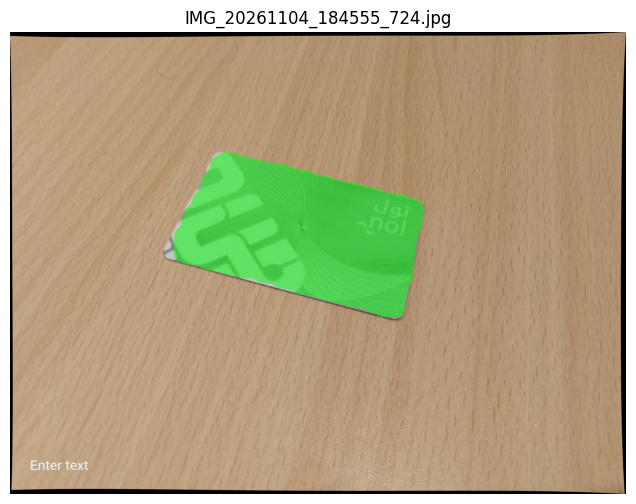

Confidence: 0.9996532201766968


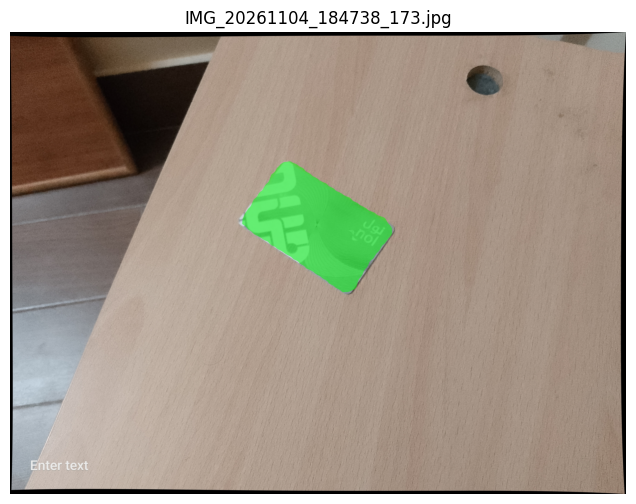

Confidence: 0.9996026158332825


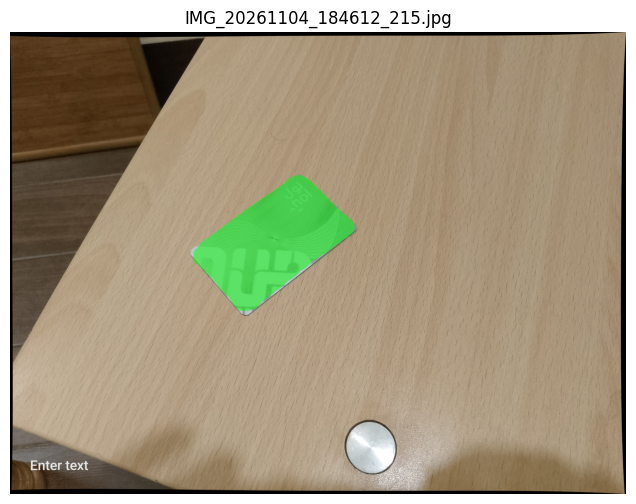

Model saved.


In [15]:
import torch
import matplotlib.pyplot as plt
import cv2
import numpy as np

# Save trained model
torch.save(model.state_dict(), "/content/maskrcnn_object.pth")

# Generate predictions on 3 validation images
model.eval()

for info in [val_images[0], val_images[5], val_images[10]]:
    path = IMAGE_DIR / info["file_name"]
    image = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)

    tensor = torch.from_numpy(image).permute(2, 0, 1).float() / 255
    tensor = tensor.to(DEVICE)

    with torch.no_grad():
        prediction = model([tensor])[0]

    result = image.copy()

    if len(prediction["scores"]) > 0:
        idx = torch.argmax(prediction["scores"]).item()
        mask = prediction["masks"][idx, 0].cpu().numpy() > 0.5

        result[mask] = (
            0.5 * result[mask] + 0.5 * np.array([0, 255, 0])
        ).astype(np.uint8)

        print("Confidence:", prediction["scores"][idx].item())

    plt.figure(figsize=(9, 6))
    plt.imshow(result)
    plt.title(info["file_name"])
    plt.axis("off")
    plt.show()

print("Model saved.")

In [17]:
from google.colab import files

uploaded = files.upload()
measurement_path = "/content/" + list(uploaded.keys())[0]

print("Measurement image:", measurement_path)

Saving IMG_20261104_205907_774.jpg to IMG_20261104_205907_774.jpg
Measurement image: /content/IMG_20261104_205907_774.jpg


In [18]:
import os

for f in os.listdir("/content"):
    if f.lower().endswith((".jpg", ".jpeg", ".png")):
        print(f)

IMG_20261104_205907_774.jpg


Image dimensions: 4160 x 3120
Detection confidence: 0.9931885004043579


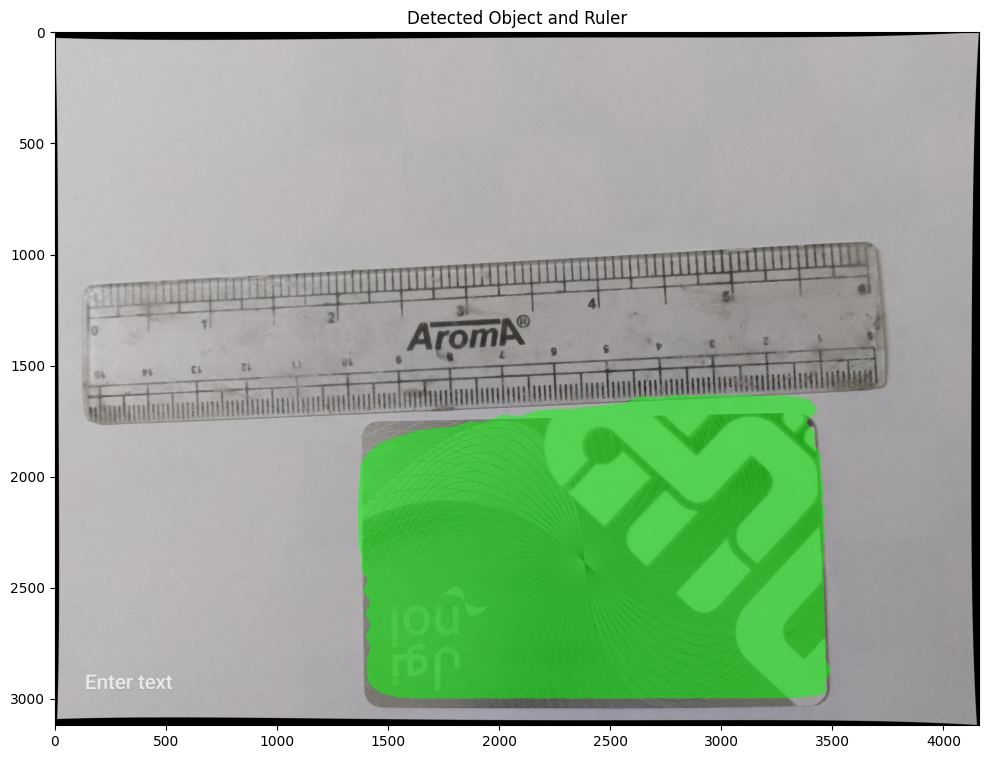

In [19]:
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

filename = "/content/IMG_20261104_205907_774.jpg"

image = cv2.imread(filename)
if image is None:
    raise FileNotFoundError(filename)

h, w = image.shape[:2]
print("Image dimensions:", w, "x", h)

# Apply camera calibration
cal = np.load("/content/camera_calibration.npz")
K = cal["camera_matrix"]
D = cal["dist_coeffs"]

if (w, h) == (4160, 3120):
    K_scaled = K.copy()
elif (w, h) == (3120, 4160):
    raise ValueError(
        "Portrait orientation detected. We need to adjust calibration "
        "for this orientation before measuring."
    )
else:
    K_scaled = K.copy()
    K_scaled[0, :] *= w / 4160
    K_scaled[1, :] *= h / 3120

new_K, roi = cv2.getOptimalNewCameraMatrix(
    K_scaled, D, (w, h), 1, (w, h)
)

undistorted = cv2.undistort(image, K_scaled, D, None, new_K)
rgb = cv2.cvtColor(undistorted, cv2.COLOR_BGR2RGB)

# Run segmentation model
tensor = torch.from_numpy(rgb).permute(2, 0, 1).float() / 255
tensor = tensor.to(DEVICE)

model.eval()
with torch.no_grad():
    output = model([tensor])[0]

if len(output["scores"]) == 0:
    raise RuntimeError("Model did not detect the object.")

idx = torch.argmax(output["scores"]).item()
mask = output["masks"][idx, 0].cpu().numpy() > 0.5

result = rgb.copy()
result[mask] = (
    0.5 * result[mask] + 0.5 * np.array([0, 255, 0])
).astype(np.uint8)

print("Detection confidence:", output["scores"][idx].item())

plt.figure(figsize=(14, 9))
plt.imshow(result)
plt.title("Detected Object and Ruler")
plt.axis("on")
plt.show()

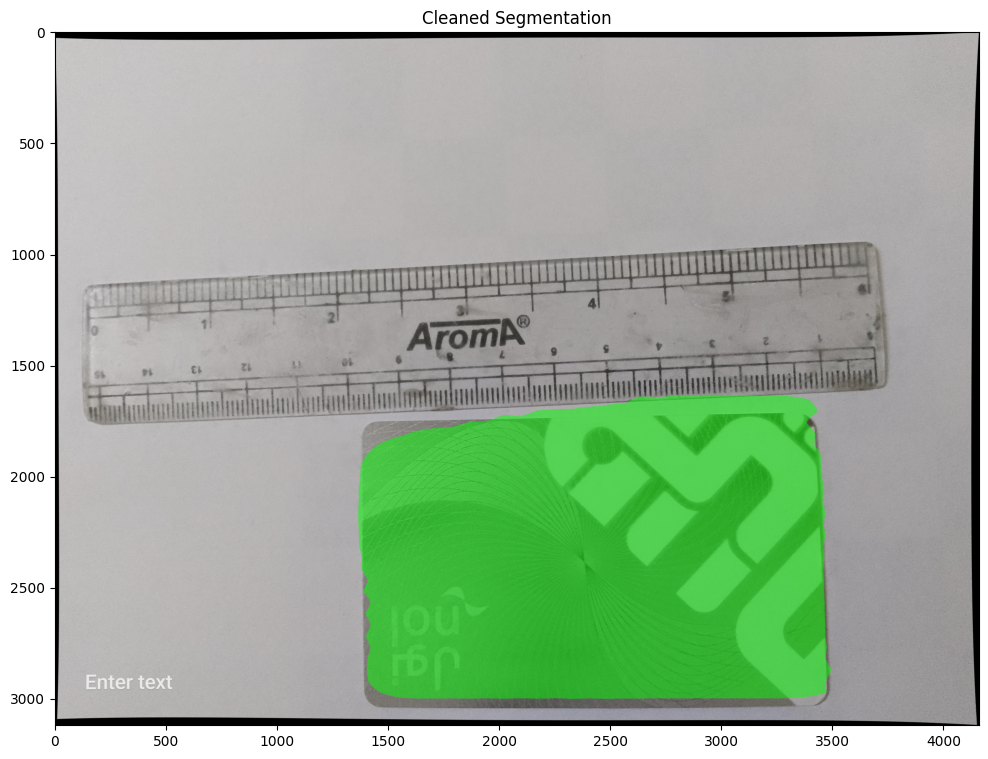

Object pixel width: 2134
Object pixel height: 1370
Detection confidence: 0.9931885004043579


In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

prob = output["masks"][idx, 0].cpu().numpy()
clean = (prob >= 0.5).astype(np.uint8)

# Keep largest connected component
count, labels, stats, centroids = cv2.connectedComponentsWithStats(clean)

if count > 1:
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    clean = (labels == largest).astype(np.uint8)

# Close small gaps
kernel = np.ones((7, 7), np.uint8)
clean = cv2.morphologyEx(clean, cv2.MORPH_CLOSE, kernel)

# Display cleaned prediction
result = rgb.copy()
result[clean == 1] = (
    0.5 * result[clean == 1] +
    0.5 * np.array([0, 255, 0])
).astype(np.uint8)

plt.figure(figsize=(14, 9))
plt.imshow(result)
plt.title("Cleaned Segmentation")
plt.axis("on")
plt.show()

ys, xs = np.where(clean == 1)
print("Object pixel width:", xs.max() - xs.min() + 1)
print("Object pixel height:", ys.max() - ys.min() + 1)
print("Detection confidence:", output["scores"][idx].item())

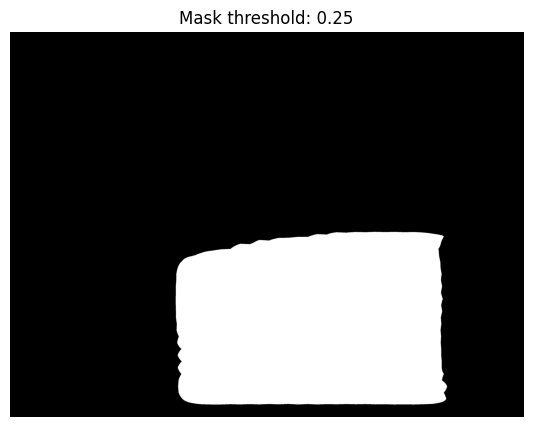

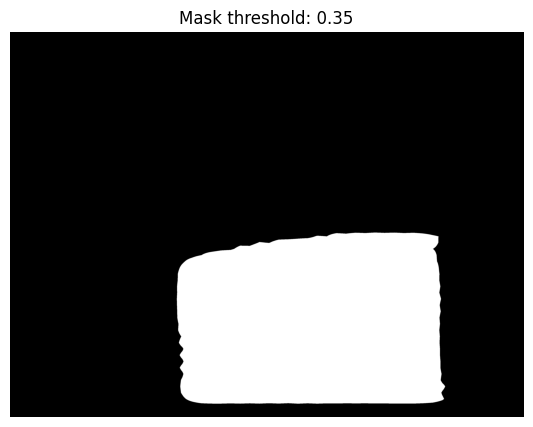

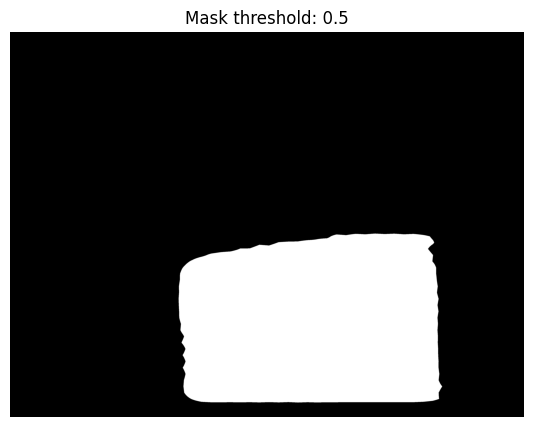

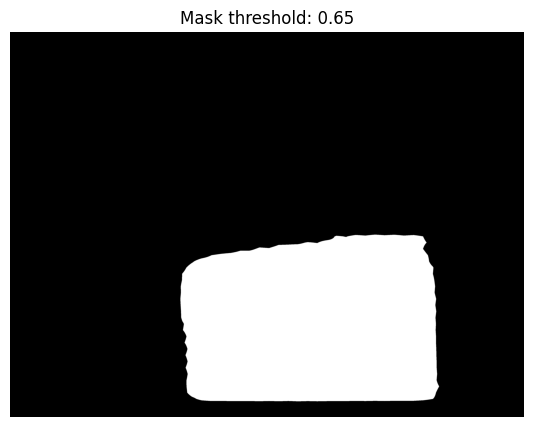

In [21]:
prob = output["masks"][idx, 0].cpu().numpy()

for threshold in [0.25, 0.35, 0.50, 0.65]:
    test_mask = (prob >= threshold).astype(np.uint8)

    plt.figure(figsize=(7, 5))
    plt.imshow(test_mask, cmap="gray")
    plt.title(f"Mask threshold: {threshold}")
    plt.axis("off")
    plt.show()

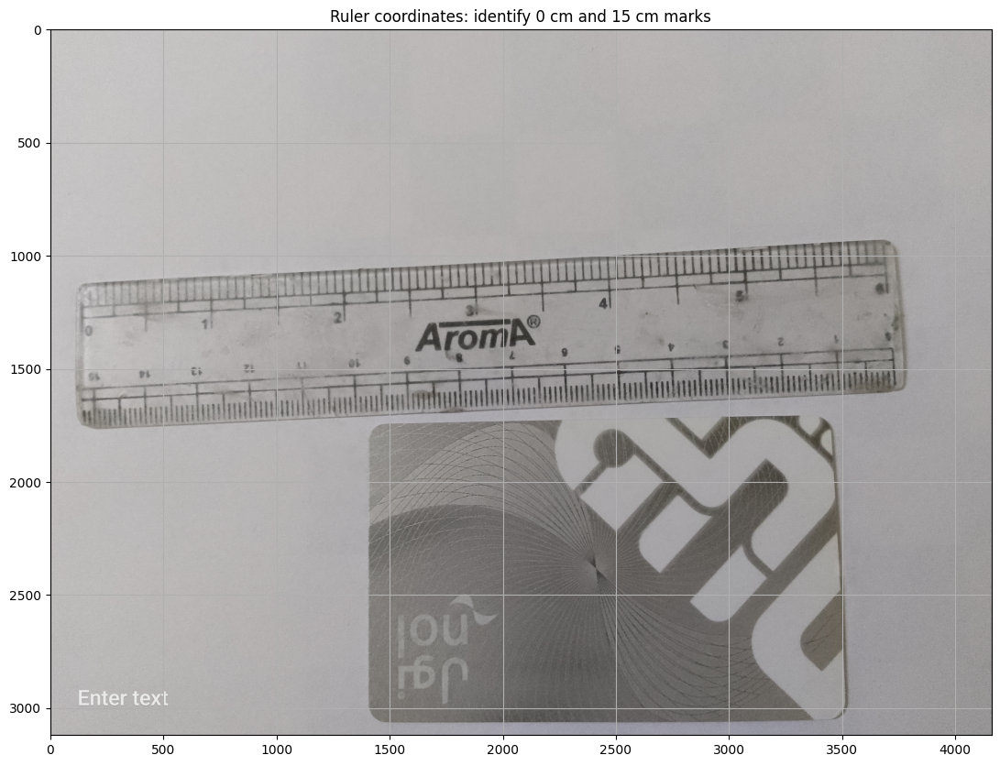

In [24]:
import cv2
import matplotlib.pyplot as plt

img = cv2.cvtColor(
    cv2.imread("/content/IMG_20261104_205907_774.jpg"),
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(16, 10))
plt.imshow(img)
plt.title("Ruler coordinates: identify 0 cm and 15 cm marks")
plt.grid()
plt.show()


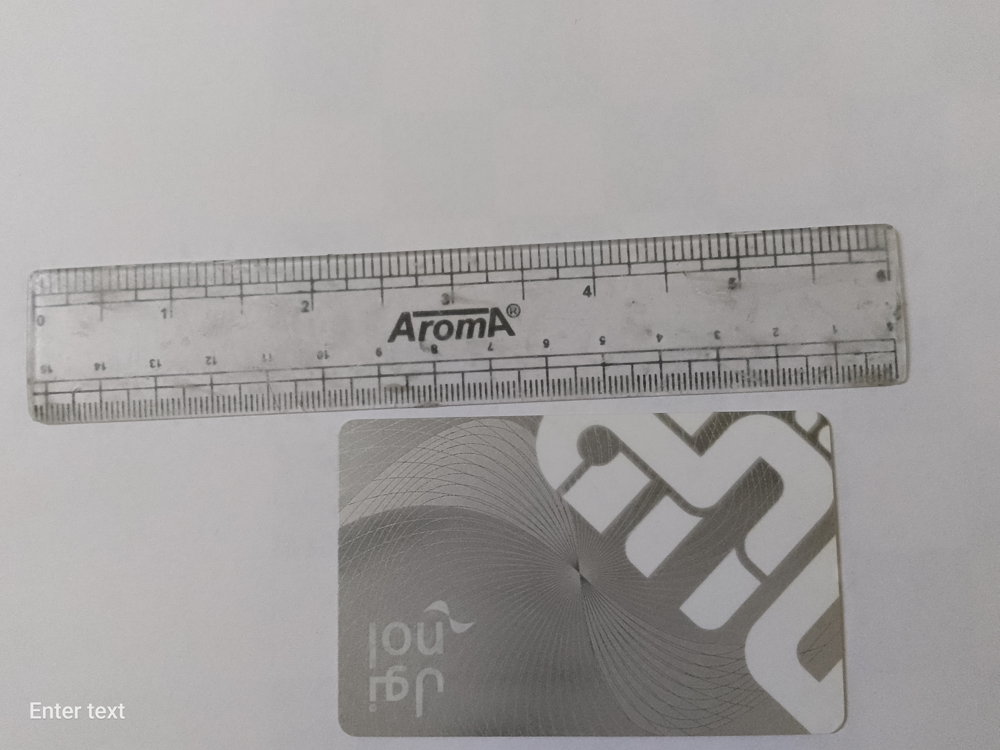

Coordinates: [[3732.4304715840385, 1587.744860943168], [196.17896009673518, 1758.7726723095525]]


In [26]:
from google.colab import output
from IPython.display import HTML, display
from base64 import b64encode
import cv2

img = cv2.imread("/content/IMG_20261104_205907_774.jpg")
h, w = img.shape[:2]
_, buf = cv2.imencode(".jpg", img)
encoded = b64encode(buf).decode()

html = """
<div>
<p>Click ruler's 0 cm mark, then 15 cm mark.</p>
<canvas id="c" style="width:100%;max-width:1000px;cursor:crosshair"></canvas>
<p id="status">0/2 clicks</p>
</div>
<script>
const c = document.getElementById('c');
const ctx = c.getContext('2d');
const im = new Image();
const pts = [];
im.onload = () => {
  c.width = im.width;
  c.height = im.height;
  ctx.drawImage(im, 0, 0);
};
im.src = 'data:image/jpeg;base64,IMAGE_DATA';
c.onclick = e => {
  const r = c.getBoundingClientRect();
  pts.push([
    (e.clientX-r.left)*c.width/r.width,
    (e.clientY-r.top)*c.height/r.height
  ]);
  document.getElementById('status').innerText = pts.length + '/2 clicks';
  if (pts.length === 2) {
    google.colab.kernel.invokeFunction('save_points', [pts], {});
  }
};
</script>
""".replace("IMAGE_DATA", encoded)

points_result = []

def save_points(p):
    global points_result
    points_result = p
    print("Coordinates:", p)

output.register_callback("save_points", save_points)
display(HTML(html))

In [27]:
import cv2
import numpy as np

# Use the existing segmentation mask
if "clean" in globals():
    obj_mask = clean
else:
    obj_mask = mask

obj_mask = (obj_mask > 0).astype(np.uint8)

contours, _ = cv2.findContours(
    obj_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

if not contours:
    print("No object detected in mask.")
else:
    largest = max(contours, key=cv2.contourArea)
    rect = cv2.minAreaRect(largest)
    width_px, height_px = rect[1]

    scale = 150 / 3540.38490347547

    dimensions = sorted([
        width_px * scale,
        height_px * scale
    ], reverse=True)

    print(f"Object dimensions: {dimensions[0]:.2f} mm × {dimensions[1]:.2f} mm")
    print(f"Manual dimensions: 86 mm × 54 mm")
    print(f"Length error: {abs(dimensions[0]-86):.2f} mm")
    print(f"Width error: {abs(dimensions[1]-54):.2f} mm")

Object dimensions: 89.37 mm × 58.41 mm
Manual dimensions: 86 mm × 54 mm
Length error: 3.37 mm
Width error: 4.41 mm


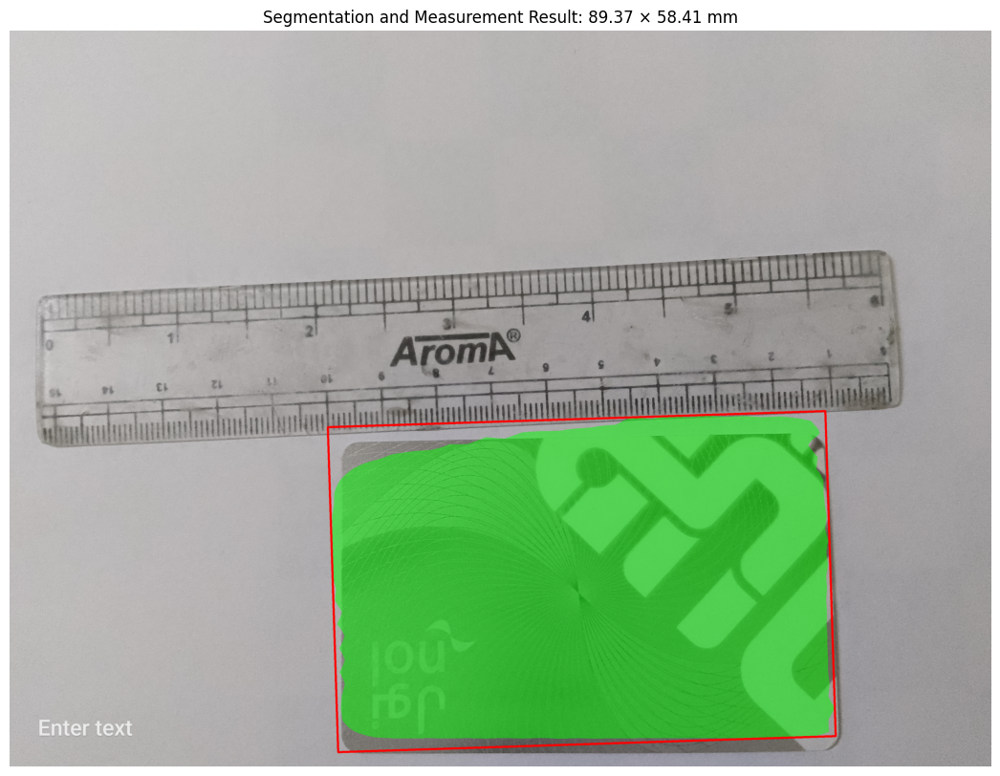

Saved: /content/measurement_result.png


In [28]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread("/content/IMG_20261104_205907_774.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

mask_uint8 = (obj_mask > 0).astype(np.uint8)
contours, _ = cv2.findContours(
    mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
largest = max(contours, key=cv2.contourArea)

overlay = img.copy()
overlay[mask_uint8 == 1] = (
    0.5 * overlay[mask_uint8 == 1] +
    0.5 * np.array([0, 255, 0])
).astype(np.uint8)

rect = cv2.minAreaRect(largest)
box = cv2.boxPoints(rect).astype(int)
cv2.drawContours(overlay, [box], 0, (255, 0, 0), 8)

plt.figure(figsize=(14, 10))
plt.imshow(overlay)
plt.title("Segmentation and Measurement Result: 89.37 × 58.41 mm")
plt.axis("off")
plt.savefig("/content/measurement_result.png", bbox_inches="tight")
plt.show()

print("Saved: /content/measurement_result.png")